In [3]:
# activation functions are what allow nn to not be purely linear
# finding a weight and a bias, which are m and c in y = mx + c

# even with multiple inputs, x1m1 + x2m2 + c =  y is still fundamentally linear
# so we add a bit of non linearaity between each layer

In [4]:
import math
import matplotlib.pyplot as plt
import numpy as np

In [5]:
detail = 1000

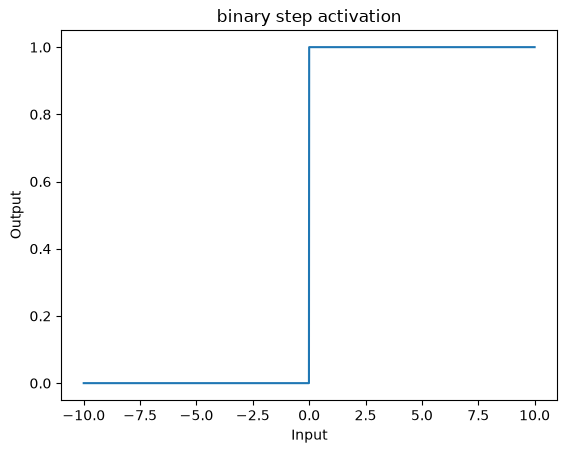

In [6]:
def binary_step(x):
    return 0 if x < 0 else 1
# print(binary_step(10))
# print(binary_step(0))
# print(binary_step(-1))

# this one kinda sucks but serves as a simple idea: this is some non linear behaviour added into the mix

x = np.linspace(-10, 10, int(2 * detail) + 1)
y = [binary_step(k) for k in x]

plt.plot(x, y)
plt.title("binary step activation")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()

In [7]:
# for backpropogation, derivatives will be required

# using the chain rule we have
# change in loss with respect to weight 
# = change in error with respect to activation * change in activation with respect to output * change in output with respect to input
# this second part is the derivative of activation function

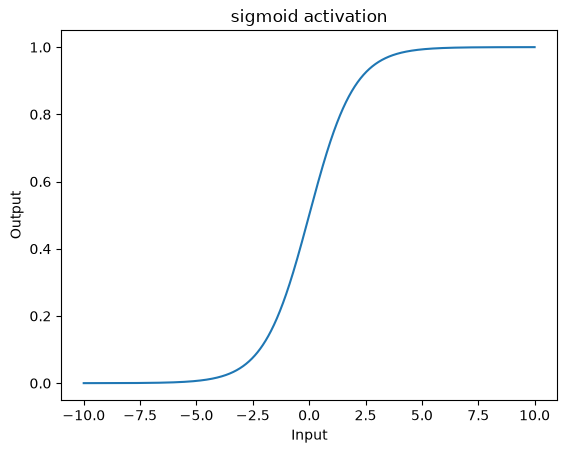

In [ ]:
def sigmoid(x):
    if x  >= 0:
        value = 1 / (1+math.e**-x)
    else:
        value = math.e**x / (1 +  math.e**x)
    return value
# uses this weird piecewise version to ensure that the powers of e dont explode 

def sigmoid_derivative(output):
    value = output * (1-output)
    return value

# also known as logistic function
# takes real numbered input and squashes between 0 and 1
# main job is converting raw output into probabilities
# used in binary classification

# max derivative of sigmoid is 0.25
# which means backprop grad is reduced by 75% each layer min
# quickly leads to backprop grad of 0, 
# thus vanishing gradient problem where early neurons no longer change

x = np.linspace(-10, 10, int(2 * detail) + 1)
y = [sigmoid(k) for k in x]

plt.plot(x, y)
plt.title("sigmoid activation")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()



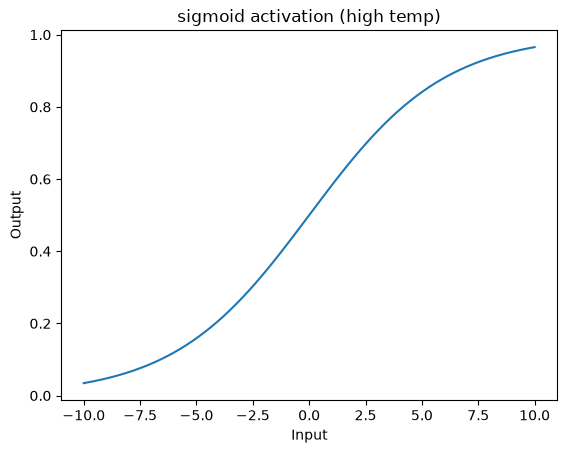

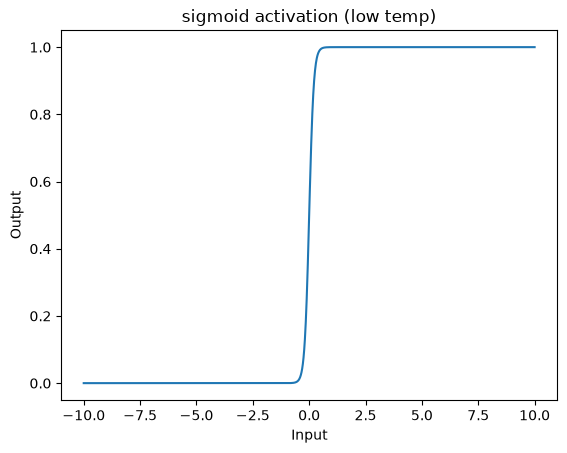

In [9]:
def sigmoid_with_temp(x,temp):
    if x  >= 0:
        value = 1 / (1+math.e**(-x/temp))
    else:
        value = math.e**(x/temp) / (1 +  math.e**(x/temp))
    return value

# temp is another controlling factor
# temp > 1: makes predictions more spread out
# temp < 1: turns into hard step function

x = np.linspace(-10, 10, int(2 * detail) + 1)
y = [sigmoid_with_temp(k,3) for k in x]

plt.plot(x, y)
plt.title("sigmoid activation (high temp)")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()

x = np.linspace(-10, 10, int(2 * detail) + 1)
y = [sigmoid_with_temp(k,0.1) for k in x]

plt.plot(x, y)
plt.title("sigmoid activation (low temp)")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()


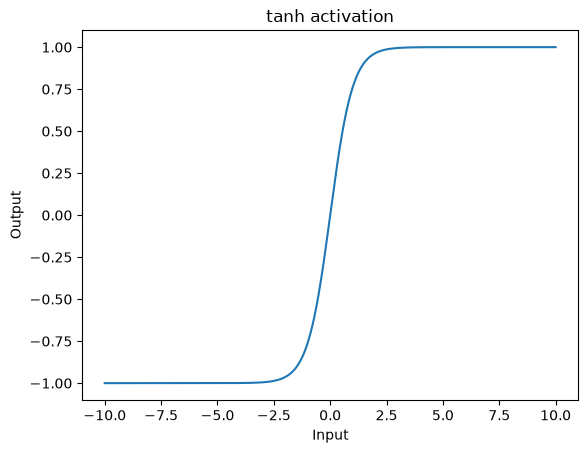

In [ ]:
# def tanh(x):
#     value = (math.e**x - math.e**-x)/(math.e**x + math.e**-x)
#     return value

# niave version of tanh blows up for same reason as sigmoid, the exponenets of e can grow ridiculously large

def tanh(x):
    if x >= 20.0:
        value = 1.0
    elif x <= -20.0:
        value =  -1.0
    else:
        exp_neg2x = math.exp(-2.0 * x)
        value = (1.0 - exp_neg2x) / (1.0 + exp_neg2x)
    return value
# at 20, its accurate to 16 dp and float64 so it should be fine

# can also be defined from sigmoid
def tanh_from_sigmoid(x):
    value = 2 * sigmoid(2*x) -1
    return value

def tanh_derivative(output):
    value = 1.0 - (output ** 2)
    return value

# tanh squishes all reals into -1 to 1
# like sigmoid, but now 0 centred
# this is better because outputs can now be negative: so inputs to next layer can now be negative
# for sigmoid, in each step, every weight moves in the same direction: up or down
# with tanh, it no longer needs to do so

# used in recurrent netwroks for its hidden gates


x = np.linspace(-10, 10, int(2 * detail) + 1)
y = [tanh(k) for k in x]

plt.plot(x, y)
plt.title("tanh activation")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()


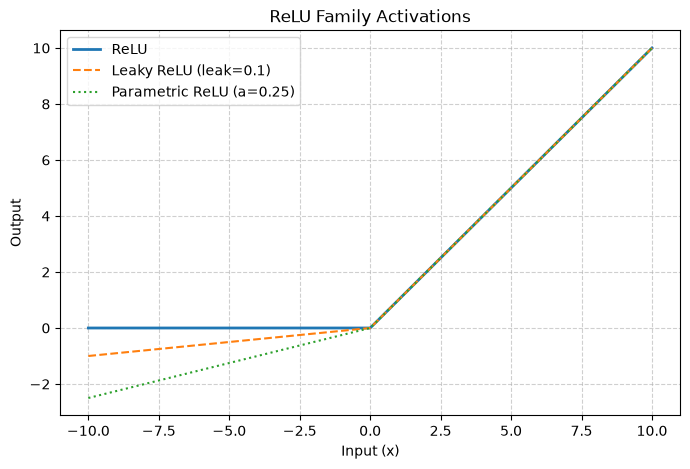

In [ ]:
def ReLU(x):
    return (max(x,0))
def Relu_derivative(input):
    value = 1 if input > 0 else 0
    return value
# kills negatives, lets positives through

# used as the activation for hidden layers in mlp and cnn
# simple and fast 
# no vanishing gradient for x > 0, allowing for much deeper than tanh/sigmoid
# but, if x < 0, dies, which leads to dead and potentially wasted neurons
# however, the dying can be useful: say for instance in a cnn, killing input neurons allow for feature seperation and noise reduction


def lRelu(x):
    return(max(x*0.1,x))
def lRelu_derivative(input):
    value = 1 if input>0 else 0.1
    return value
# solves the dying with a little negative pass through


def pRelu(x,a):
    return(max(a*x,x))
def pRelu_derivative(input, a):
    value = 1 if input > 0 else a
    return value
# learns how much to let through
# note lrelu, prelu use input to calc derivative

detail = 10
x = np.linspace(-10, 10, int(2 * detail) + 1)

# Evaluating each function over the input range
y_relu = [ReLU(k) for k in x]
y_lrelu = [lRelu(k) for k in x]
y_prelu = [pRelu(k, a=0.25) for k in x]  # using a sample slope a = 0.25

plt.figure(figsize=(8, 5))
plt.plot(x, y_relu, label="ReLU", linewidth=2)
plt.plot(x, y_lrelu, label="Leaky ReLU (leak=0.1)", linestyle="--")
plt.plot(x, y_prelu, label="Parametric ReLU (a=0.25)", linestyle=":")

plt.title("ReLU Family Activations")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

Raw Logits:            [2.0, 1.0, 0.1, 4.5]
Softmax Probabilities: [0.073, 0.0269, 0.0109, 0.8892]
Sum of Probabilities:  1.0


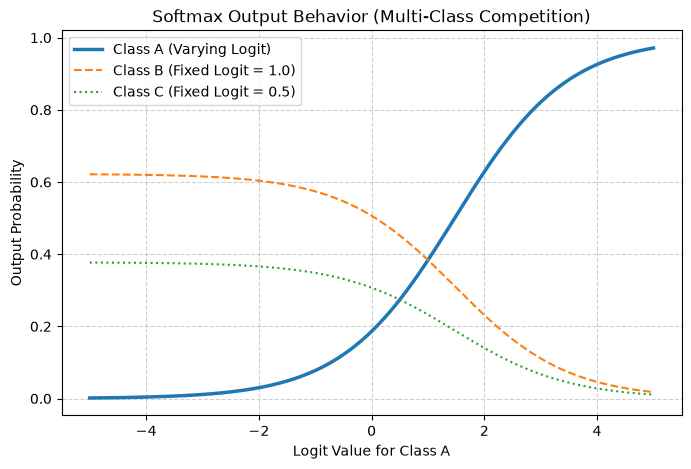

In [ ]:
# def softmax_naive(logits):
#     exp_values = [math.exp(x) for x in logits]
#     sum_exp = sum(exp_values)
#     return [x / sum_exp for x in exp_values]

# converts vector of numbers into true probability distribution

# like others, might break if the exponent is too large

def softmax(logits):
    max_logit = max(logits)
    exp_values = [math.exp(x - max_logit) for x in logits]
    sum_exp = sum(exp_values)
    return [x / sum_exp for x in exp_values]

# used in output layer of multi class classification

# example of it turning random vector into probability distribution
raw_logits = [2.0, 1.0, 0.1, 4.5]
probs = softmax(raw_logits)

print(f"Raw Logits:            {raw_logits}")
print(f"Softmax Probabilities: {[round(p, 4) for p in probs]}")
print(f"Sum of Probabilities:  {sum(probs):.1f}")

# x_logits = np.linspace(-5, 5, 200)
# class_a_probs = []
# class_b_probs = []
# class_c_probs = []

# for val in x_logits:
#     p = softmax([val, 1.0, 0.5])
#     class_a_probs.append(p[0])
#     class_b_probs.append(p[1])
#     class_c_probs.append(p[2])

# plt.figure(figsize=(8, 5))
# plt.plot(x_logits, class_a_probs, label="Class A (Varying Logit)", linewidth=2.5)
# plt.plot(x_logits, class_b_probs, label="Class B (Fixed Logit = 1.0)", linestyle="--")
# plt.plot(x_logits, class_c_probs, label="Class C (Fixed Logit = 0.5)", linestyle=":")

# plt.title("Softmax Output Behavior (Multi-Class Competition)")
# plt.xlabel("Logit Value for Class A")
# plt.ylabel("Output Probability")
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.legend()
# plt.show()

In [ ]:
# loss functions serves as the networks feedback mechanism
# basically how wrong it is

# quantifies errors: a score of 0 is perfect
# get to choose what kind of behaviours to penalise